In [219]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [300]:
## part 1: finding the response
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47 

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.6,speckle_window=50)
PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

least-squares solution: (4.570940591815358,-0.15129107674825756)
Estimated dispersion direction -178.1042902069719°
Estimated dispersion magnitude 4.573443657006062


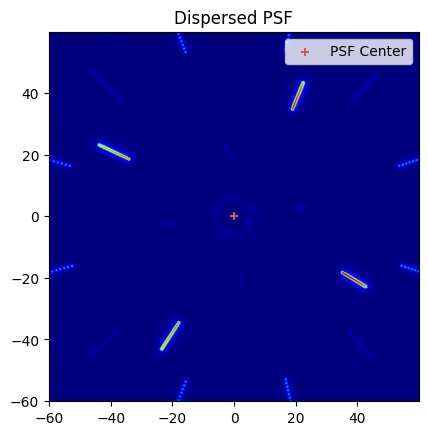

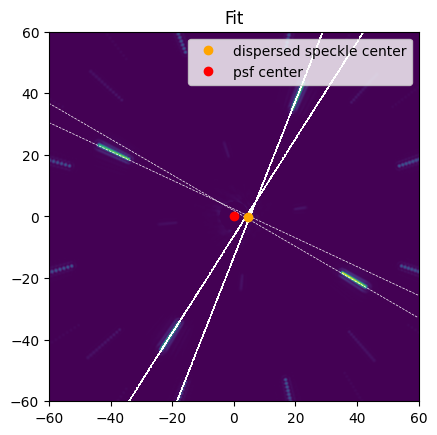

In [255]:
#sample PSF with dispersion measurement
# disp_x = np.random.rand() * 0.1
# disp_y = np.random.rand() * 0.1

# #these two parameters define the atmospheric dispersion vector
# disp_mag = np.sqrt(disp_x**2 + disp_y**2)
# disp_ang = np.atan(disp_y / disp_x)

disp = 0.05
ang = 0

num_photons = 1E9
#psf = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=num_photons,ptv=0)
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)

true_center = np.array([0,0]) #we can worry about how well we can estimate this later


imshow_field(psf,cmap='jet')
plt.scatter(true_center[0],true_center[1],marker='+',color='indianred',label='PSF Center')
plt.legend()
plt.title('Dispersed PSF')

plt.figure()
est = ADC.speckles_dxdy(psf,plotted=True,printed=True)
plt.title('Fit')
plt.show()

now we need to define the ADC dispersion vector
 - to do this we need to know the response - the /orthogonal/ response, to be precise
 - but this is something we don't really know with the simulation, since the ADC isn't actually moving. therefore, the ADC response will be calibrated to match something similar to the real system
 - in the calibrations from feb 20, the shearing response changed the magnitude of the dispersion vector by 1.3 pixels/degree shear
 - we'll assume that the orientation is 1:1 degrees/degrees - this can be changed once i understand the real behavior better

In [222]:
#these two quantities will define the ADC behavior, and will be used to create the ADC dispersion vector
adc_shear = 0
adc_rot = 0

#this is the actual ADC dispersion vector
adc_dx = adc_shear * np.cos(np.radians(adc_rot))
adc_dy = adc_shear * np.sin(np.radians(adc_rot))

#the ADC NCPC orthogonal response
m00 = 1/1.3 #degrees/pixel
m01 = 1 #degrees/degree 

notes:
- the slope of the dx plot is the same as the slope of the shear plot when the speckles are orthogonal to the axis of dispersion
- there is a degeneracy between positive and negative shear angles when we only measure the length of the dispersion vector. this is why the direction becomes especially important.

Now let's look at what happens when the dispersion axis is not exactly orthogonal:

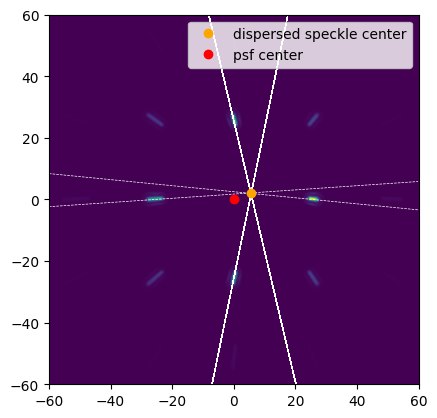

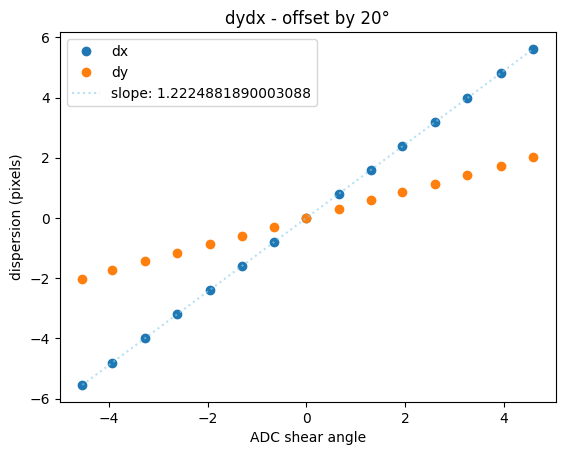

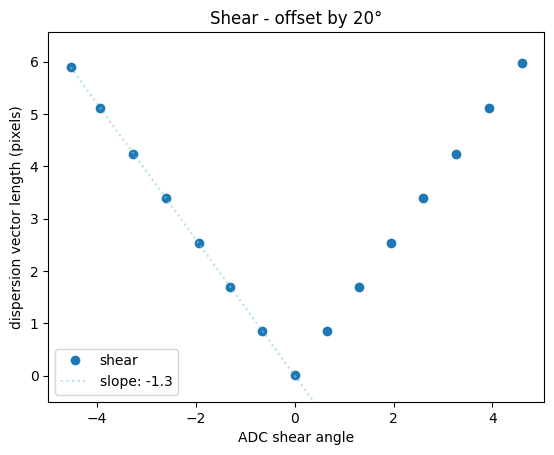

In [223]:
disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
dir = 20 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps

num_photons = 1E12

dx_list = []
dy_list = []

for i, disp in enumerate(disps_x):
    psf = PsfGen.psf(magnitude_x=disp,magnitude_y=disps_y[i])
    est = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    dx_list.append(est[0])
    dy_list.append(est[1])

ADC.speckles_dxdy(psf,plotted=True,printed=False)
imshow_field(psf)
plt.show()

dx_list = np.array(dx_list)
dy_list = np.array(dy_list)

#now convert these dx and dy estimates into ADC shear and rotation angles, ASSUMING THE DISPERSION AXIS IS ORTHOGONAL TO THE ADC AXIS
sq = np.sqrt(np.sum(np.vstack((dx_list**2,dy_list**2)),axis=0)) #magnitude of each dispersion vector
ang = np.arctan2(dy_list,dx_list) #orientation of each dispersion vector - this will error out if the angle is 90°, which it is in this case

adc_shear = m00 * sq
adc_shear[:7] = -adc_shear[:7]
adc_rot = m01 * ang

m1, b1 = np.polyfit(adc_shear,dx_list,deg=1)

plt.plot(adc_shear,dx_list,'o',label='dx')
plt.plot(adc_shear,dy_list,'o',label='dy')
linepoints = b1 + m1 * adc_shear
plt.plot(adc_shear,linepoints,label=f'slope: {m1}',linestyle='dotted',color='skyblue',alpha=0.6)
plt.xlabel('ADC shear angle')
plt.ylabel('dispersion (pixels)')
plt.title(f'dydx - offset by {dir}°')
plt.legend()
plt.show()

m2, b2 = np.polyfit(adc_shear[:7],sq[:7],deg=1)

plt.figure()
plt.plot(adc_shear,sq,'o',label='shear')
linepoints2 = b2 + m2 * adc_shear
plt.plot(adc_shear,linepoints2,label=f'slope: {m2}',linestyle='dotted',color='skyblue',alpha=0.6)
plt.xlabel('ADC shear angle')
plt.ylabel('dispersion vector length (pixels)')
plt.title(f'Shear - offset by {dir}°')
plt.ylim(bottom=-0.5)
plt.legend()
plt.show()

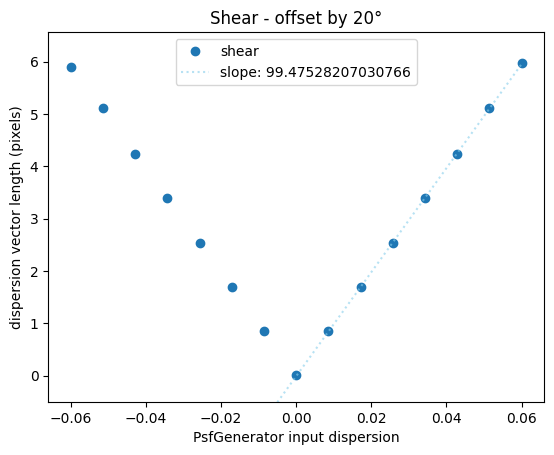

In [224]:
#this will become important for when we try to simulate the controller
m3, b3 = np.polyfit(disps[8:],sq[8:],deg=1)
m02 = m3 #pixels/arb. dispersion input

plt.figure()
plt.plot(disps,sq,'o',label='shear')
linepoints3 = b3 + m3 * disps
plt.plot(disps,linepoints3,label=f'slope: {m3}',linestyle='dotted',color='skyblue',alpha=0.6)
plt.xlabel('PsfGenerator input dispersion')
plt.ylabel('dispersion vector length (pixels)')
plt.title(f'Shear - offset by {dir}°')
plt.ylim(bottom=-0.5)
plt.legend()
plt.show()

In [225]:
#let's plot how the slope of the dx line changes based on the offset between the ADC axis and the dispersion axis
disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
dir = 90 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps

num_photons = 1E12

dirs = np.linspace(0,90,20)
dx_slopes = []

for j, dir in enumerate(dirs):
    disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps


    dx_list = []
    dy_list = []

    for i, disp in enumerate(disps_x):
        psf = PsfGen.psf(magnitude_x=disp,magnitude_y=disps_y[i])
        est = ADC.speckles_dxdy(psf,plotted=False,printed=False)
        dx_list.append(est[0])
        dy_list.append(est[1])

    dx_list = np.array(dx_list)
    dy_list = np.array(dy_list)

    #now convert these dx and dy estimates into ADC shear and rotation angles, ASSUMING THE DISPERSION AXIS IS ORTHOGONAL TO THE ADC AXIS
    sq = np.sqrt(np.sum(np.vstack((dx_list**2,dy_list**2)),axis=0)) #magnitude of each dispersion vector
    ang = np.arctan2(dy_list,dx_list) #orientation of each dispersion vector - this will error out if the angle is 90°, which it is in this case

    adc_shear = m00 * sq
    adc_shear[:7] = -adc_shear[:7]
    adc_rot = m01 * ang

    m1, b1 = np.polyfit(adc_shear,dx_list,deg=1)
    dx_slopes.append(m1)


[1.00162063 0.00194585 1.29990443]


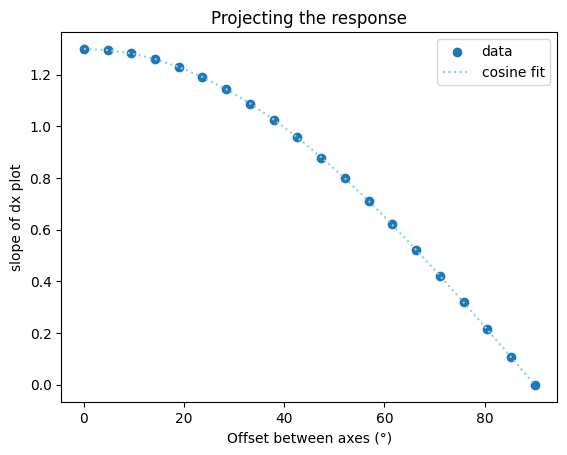

In [226]:
def cosine(angs,stretch,shift,amp):
    angs = np.radians(angs)
    return np.cos(angs * stretch - shift) * amp


dx_slopes = np.array(dx_slopes)

popt, *_ = curve_fit(cosine,dirs,dx_slopes)
print(popt)
fit = cosine(dirs,*popt)

# m, b = np.polyfit(dirs,dx_slopes,deg=1)
# linepoints = b + m * dirs

plt.figure()
plt.scatter(dirs,dx_slopes,label='data')
plt.plot(dirs,fit,linestyle='dotted',color='skyblue',label='cosine fit')
#plt.plot(dirs,linepoints,linestyle='dotted',color='skyblue',alpha=0.6,label=f'slope: {m}')
plt.xlabel('Offset between axes (°)')
plt.ylabel('slope of dx plot')
plt.title('Projecting the response')
plt.legend()
plt.show()

In [227]:
#same thing except it's the speckle angle pairs instead of dx that we're comparing against
disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
dir = 90 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps

num_photons = 1E12

dirs = np.linspace(0,90,20)
pair_slopes24 = []

for j, dir in enumerate(dirs):
    disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps


    pair24 = []
    dx_list = []
    dy_list = []

    for i, disp in enumerate(disps_x):
        psf = PsfGen.psf(magnitude_x=disp,magnitude_y=disps_y[i])
        est = ADC.speckles_dxdy(psf,plotted=False,printed=False)
        est1 = ADC.speckle_pairs(ADC.all_speckle_angles(psf))
        pair24.append(est1[1])
        dx_list.append(est[0])
        dy_list.append(est[1])

    dx_list = np.array(dx_list)
    dy_list = np.array(dy_list)
    pair24 = np.array(pair24)

    #now convert these dx and dy estimates into ADC shear and rotation angles, ASSUMING THE DISPERSION AXIS IS ORTHOGONAL TO THE ADC AXIS
    sq = np.sqrt(np.sum(np.vstack((dx_list**2,dy_list**2)),axis=0)) #magnitude of each dispersion vector
    ang = np.arctan2(dy_list,dx_list) #orientation of each dispersion vector - this will error out if the angle is 90°, which it is in this case

    adc_shear = m00 * sq
    adc_shear[:7] = -adc_shear[:7]
    adc_rot = m01 * ang

    m1, b1 = np.polyfit(adc_shear,pair24,deg=1)
    pair_slopes24.append(m1)


[ 1.02957999  1.5673007  -5.72122623]


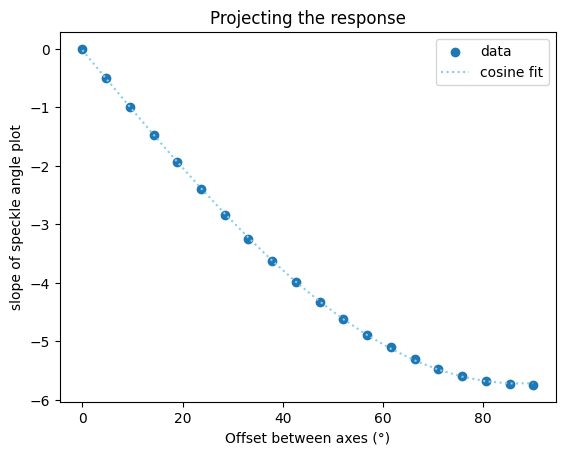

In [228]:
popt, *_ = curve_fit(cosine,dirs,pair_slopes24)
print(popt)
fit = cosine(dirs,*popt)

plt.figure()
plt.scatter(dirs,pair_slopes24,label='data')
plt.plot(dirs,fit,linestyle='dotted',color='skyblue',label='cosine fit')
plt.xlabel('Offset between axes (°)')
plt.ylabel('slope of speckle angle plot')
plt.title('Projecting the response')
plt.legend()
plt.show()

That's pretty definitive - the response of the speckles changes with the cosine of the angle between the dispersion axis and the ADC axis. The amplitude of the cosine will depend on the separation and waveband of the speckles. 

But, if I instead do the control using the magnitude and orientation of the dispersion, it shouldn't matter what the relative orientations are, since i'm measuring it in the 2D image plane instead of just along one axis

injected dispersion dx: [0.0145531] dy: [-0.0145531]
est dispersion 2.104177467277308 pixels
est disp axis -45.95966744895762°
est ADC shear angle: -1.6185980517517753°
est ADC rot angle: 45.95966744895762°
remaining dispersion: [-0.00057158]
remaining axis offset 0.9596674489576174


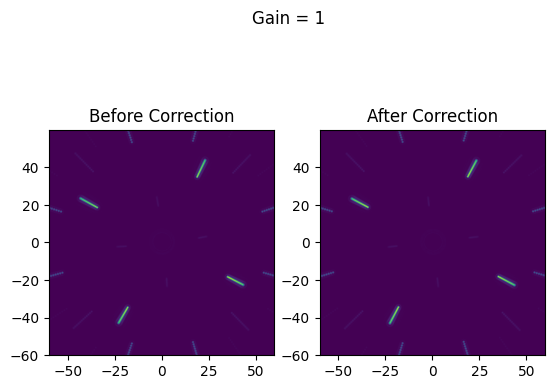

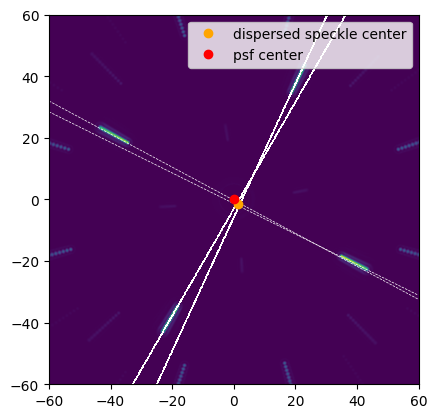

In [295]:
#one single iteration with a gain of one, before I put it in an integrator
#the response
m00 = 1/1.3 #degrees/pixel
m01 = 1 #degrees/degree 
m02 = m3 #pixels/arb. dispersion input

#set up dispersed PSF
disps =  np.abs(np.random.randn(1))*.03#-0.08 + np.abs(np.random.randn(1))*.02
dir = -45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')

psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)

fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

#now try and measure it
plt.figure()
est_x, est_y = ADC.speckles_dxdy(psf,plotted=True,printed=False)
sq = np.sqrt(est_x**2+est_y**2)
ang = np.degrees(np.arctan2(est_y,est_x))
print(f'est dispersion {sq} pixels')
print(f'est disp axis {ang}°')

#calculate how much to move ADCs
#get the correct quadrant
if est_x >0 and est_y>0:
    sign = -1
elif est_x <0 and est_y>0:
    sign = 1
elif est_x <0 and est_y<0:
    sign = 1
else: sign = -1
    
shear_est = sign * m00 * sq
rot_est = sign * ang #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
print(f'est ADC shear angle: {shear_est}°')
print(f'est ADC rot angle: {rot_est}°')

#integrate (gain of one)
disps =  disps + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
dir = dir + rot_est
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps
psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)
print(f'remaining dispersion: {disps}')
print(f'remaining axis offset {dir}')

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle('Gain = 1')
plt.show()

### Closed-loop correction using this new approach

injected dispersion dx: [-0.0096488] dy: [0.0088465]


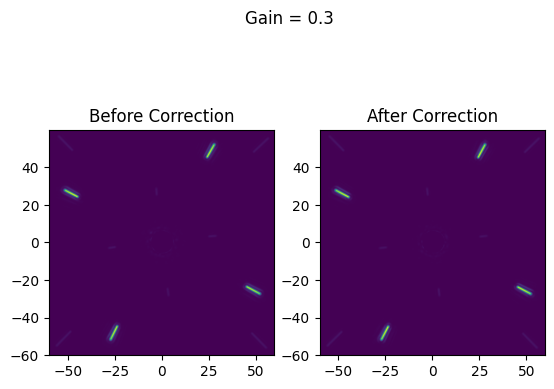

In [304]:
#now a full iterative thing with gain:
induced_disp = -np.abs(np.random.randn(1))*.05
induced_dir = -45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * induced_disp
disps_y = np.sin(np.radians(dir)) * induced_disp
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')
shear_est = 0
rot_est = 0

num_iterations = 10
gain = 0.3

disp_tracker = []
ang_tracker = []

psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)
fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

for i in range(num_iterations):
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    if est_x >0 and est_y>0:
        sign = -1
    elif est_x <0 and est_y>0:
        sign = 1
    elif est_x <0 and est_y<0:
        sign = 1
    else: sign = -1
        
    shear_est += sign * m00 * sq * gain
    rot_est += sign * ang * gain #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
    # print(f'est ADC shear angle: {shear_est}°')
    # print(f'est ADC rot angle: {rot_est}°')

    #integrate (gain of one)
    disps = induced_disp + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    dir = induced_dir + rot_est
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps
    # print(f'remaining dispersion: {disps}')
    # print(f'remaining axis offset {dir}')
    disp_tracker.append(disps)
    ang_tracker.append(dir)

    psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)

disp_tracker = np.array(disp_tracker) * m02 * m00

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

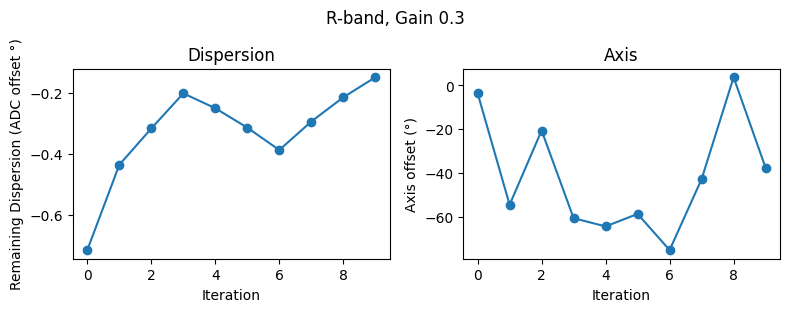

In [305]:
#plot the behavior as it goes through the iterations

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'R-band, Gain {gain}')
fig.tight_layout()
plt.show()

In [269]:
print(disp_tracker[2])
print(ang_tracker[2])

[0.01964169]
20.13872311669043


I need to understand if the method I'm using gives me the level of precision that I need. To do this, make the loop run for much longer than it needs to converge and look at the variance of the points after the point of convergence

injected dispersion dx: [0.01209036] dy: [0.00400187]


/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


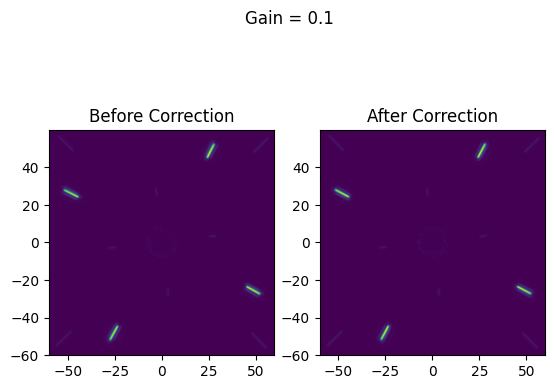

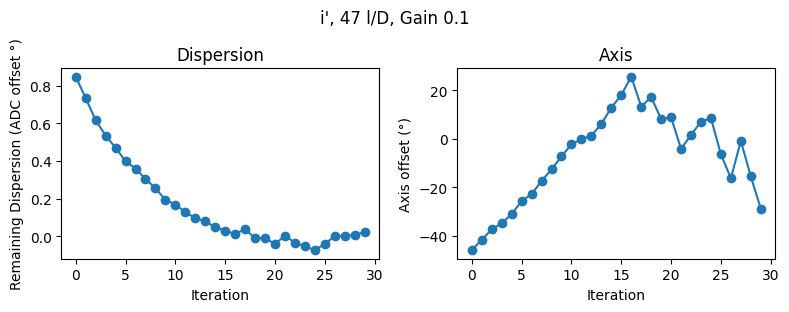

In [310]:
#now a full iterative thing with gain:
induced_disp =  np.abs(np.random.randn(1))*.03
induced_dir = -45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * induced_disp
disps_y = np.sin(np.radians(dir)) * induced_disp
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')
shear_est = 0
rot_est = 0

num_iterations = 30
gain = 0.1

disp_tracker = []
ang_tracker = []

psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)
fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

for i in range(num_iterations):
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    if est_x >0 and est_y>0:
        sign = -1
    elif est_x <0 and est_y>0:
        sign = 1
    elif est_x <0 and est_y<0:
        sign = 1
    else: sign = -1
        
    shear_est += sign * m00 * sq * gain
    rot_est += sign * ang * gain #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
    # print(f'est ADC shear angle: {shear_est}°')
    # print(f'est ADC rot angle: {rot_est}°')

    #integrate (gain of one)
    disps = induced_disp + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    dir = induced_dir + rot_est
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps
    # print(f'remaining dispersion: {disps}')
    # print(f'remaining axis offset {dir}')
    disp_tracker.append(disps)
    ang_tracker.append(dir)

    psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)

disp_tracker = np.array(disp_tracker) * m02 * m00

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')
fig.tight_layout()
plt.show()